Feature Engineering: It is the process of creating new and better features for our mOdel from which we can have better insights or we can make better prediction model.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

In [8]:
tested = pd.read_csv('E:/Chaithra/genAI/13_ML/EDA/tested.csv') # titanic dataset
newTrain = pd.read_csv("train.csv")
newTest = pd.read_csv("test.csv")

# Insert column at index 2
#newTrain.insert(1, 'Survived', tested['Survived'].values)
newTest.insert(1, 'Survived', tested['Survived'].values)

# Save updated CSV
newTrain.to_csv("UpdatedTrain.csv", index=False)
newTest.to_csv("UpdatedTest.csv", index=False)

In [25]:
train = pd.read_csv('UpdatedTrain.csv') # titanic dataset


In [24]:
test = pd.read_csv('UpdatedTest.csv') # titanic dataset

In [26]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [27]:
test.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [13]:
train.shape

(418, 12)

In [28]:
test.shape

(418, 12)

In [33]:
df = pd.concat([train,test])

In [34]:
df.shape

(1309, 12)

In [36]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [37]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
413,1305,0,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,0,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S
417,1309,0,3,"Peter, Master. Michael J",male,NaN,1,1,2668,22.3583,NaN,C


In [38]:
df.sample(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
350,1242,1,1,"Greenfield, Mrs. Leo David (Blanche Strouse)",female,45.0,0,1,PC 17759,63.3583,D10 D12,C
349,350,0,3,"Dimic, Mr. Jovan",male,42.0,0,0,315088,8.6625,NaN,S
733,734,0,2,"Berriman, Mr. William John",male,23.0,0,0,28425,13.0000,NaN,S
322,1214,0,2,"Nesson, Mr. Israel",male,26.0,0,0,244368,13.0000,F2,S
724,725,1,1,"Chambers, Mr. Norman Campbell",male,27.0,1,0,113806,53.1000,E8,S
694,695,0,1,"Weir, Col. John",male,60.0,0,0,113800,26.5500,NaN,S
403,1295,0,1,"Carrau, Mr. Jose Pedro",male,17.0,0,0,113059,47.1000,NaN,S
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
12,904,1,1,"Snyder, Mrs. John Pillsbury (Nelle Stevenson)",female,23.0,1,0,21228,82.2667,B45,S
23,915,0,1,"Williams, Mr. Richard Norris II",male,21.0,0,1,PC 17597,61.3792,NaN,C


In [40]:
# new feature: Family size = passanger+ sibSp+parCh
# comparing family size vs surival colum
# what are the chances of surival based on family size
df['Family Size'] = df['SibSp']+df['Parch'] + 1


In [41]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Family Size
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1


<Axes: xlabel='Family Size', ylabel='Survived'>

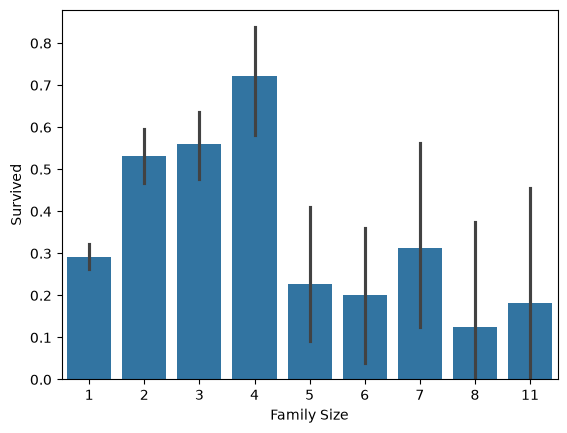

In [42]:
sns.barplot(data=df,x='Family Size',y='Survived')

In [ ]:
# 2nd feture:
    # if family size<3 then call it as small family and 
    # if family size >=3 and family size<5 then its medium family
    # and if family size>5 then large size family
    # in Small size and medium size and large size family what are the chances of survival?
def fam_type(num):
    if num>=1 and num<=3:
        return 'Small Family'
    elif num>=3 and num<=5:
        return 'Medium Family'
    else:
        return 'Large Family'


In [44]:
df['Family Type'] = df['Family Size'].apply(fam_type)

In [45]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Family Size,Family Type
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2,Small Family
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2,Small Family
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1,Small Family
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2,Small Family
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,Small Family


In [46]:
df['Family Type'].value_counts()

Family Type
Small Family     1184
Medium Family      65
Large Family       60
Name: count, dtype: int64

In [ ]:
#print(df.columns[df.columns.duplicated()])

#print("Unique index:", df.index.is_unique)

#print("Duplicate indexes:", df.index[df.index.duplicated()])
df = df.reset_index(drop=True)
print(df.index.is_unique)

#df = pd.concat([df1, df2], ignore_index=True) this can be used earlier step also

True


In [52]:
pd.crosstab(df['Family Type'],df['Survived'])

Survived,0,1
Family Type,,
Large Family,47,13
Medium Family,29,36
Small Family,739,445


In [53]:
pd.crosstab(df['Family Type'],df['Survived'],normalize=True)*100

Survived,0,1
Family Type,,
Large Family,3.590527,0.993125
Medium Family,2.215432,2.750191
Small Family,56.455309,33.995416


<Axes: xlabel='Survived', ylabel='Family Type'>

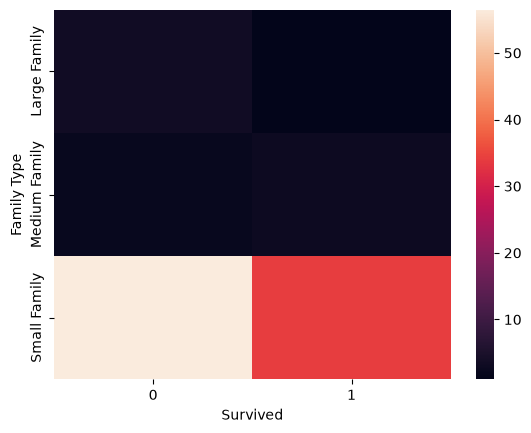

In [54]:
sns.heatmap(pd.crosstab(df['Family Type'],df['Survived'],normalize=True)*100)

In [55]:
df[df['SibSp']==5]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Family Size,Family Type
59,60,0,3,"Goodwin, Master. William Frederick",male,11.0,5,2,CA 2144,46.9,NaN,S,8,Large Family
71,72,0,3,"Goodwin, Miss. Lillian Amy",female,16.0,5,2,CA 2144,46.9,NaN,S,8,Large Family
386,387,0,3,"Goodwin, Master. Sidney Leonard",male,1.0,5,2,CA 2144,46.9,NaN,S,8,Large Family
480,481,0,3,"Goodwin, Master. Harold Victor",male,9.0,5,2,CA 2144,46.9,NaN,S,8,Large Family
683,684,0,3,"Goodwin, Mr. Charles Edward",male,14.0,5,2,CA 2144,46.9,NaN,S,8,Large Family
1031,1032,1,3,"Goodwin, Miss. Jessie Allis",female,10.0,5,2,CA 2144,46.9,NaN,S,8,Large Family


In [59]:
df['Individual Fare']= (df['Fare']/df['Family Size'])

In [60]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Family Size,Family Type,Individual Fare
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2,Small Family,3.62500
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2,Small Family,35.64165
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1,Small Family,7.92500
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2,Small Family,26.55000
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,Small Family,8.05000


In [64]:
df[df['Ticket']== 'CA 2144']

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Family Size,Family Type,Individual Fare
59,60,0,3,"Goodwin, Master. William Frederick",male,11.0,5,2,CA 2144,46.9,NaN,S,8,Large Family,5.8625
71,72,0,3,"Goodwin, Miss. Lillian Amy",female,16.0,5,2,CA 2144,46.9,NaN,S,8,Large Family,5.8625
386,387,0,3,"Goodwin, Master. Sidney Leonard",male,1.0,5,2,CA 2144,46.9,NaN,S,8,Large Family,5.8625
480,481,0,3,"Goodwin, Master. Harold Victor",male,9.0,5,2,CA 2144,46.9,NaN,S,8,Large Family,5.8625
678,679,0,3,"Goodwin, Mrs. Frederick (Augusta Tyler)",female,43.0,1,6,CA 2144,46.9,NaN,S,8,Large Family,5.8625
683,684,0,3,"Goodwin, Mr. Charles Edward",male,14.0,5,2,CA 2144,46.9,NaN,S,8,Large Family,5.8625
1030,1031,0,3,"Goodwin, Mr. Charles Frederick",male,40.0,1,6,CA 2144,46.9,NaN,S,8,Large Family,5.8625
1031,1032,1,3,"Goodwin, Miss. Jessie Allis",female,10.0,5,2,CA 2144,46.9,NaN,S,8,Large Family,5.8625


In [65]:
df[df['Ticket']== 'CA 2144'][['Name','Fare','Individual Fare']]

,Name,Fare,Individual Fare
59,"Goodwin, Master. William Frederick",46.9,5.8625
71,"Goodwin, Miss. Lillian Amy",46.9,5.8625
386,"Goodwin, Master. Sidney Leonard",46.9,5.8625
480,"Goodwin, Master. Harold Victor",46.9,5.8625
678,"Goodwin, Mrs. Frederick (Augusta Tyler)",46.9,5.8625
683,"Goodwin, Mr. Charles Edward",46.9,5.8625
1030,"Goodwin, Mr. Charles Frederick",46.9,5.8625
1031,"Goodwin, Miss. Jessie Allis",46.9,5.8625


In [66]:
5.8625*8

46.9

<Axes: xlabel='Family Size', ylabel='Fare'>

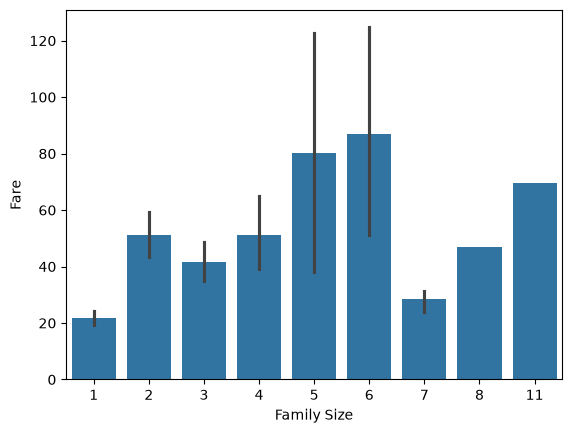

In [68]:
sns.barplot(data=df,x='Family Size',y='Fare')

In [69]:
df['Name']

0                                 Braund, Mr. Owen Harris
1       Cumings, Mrs. John Bradley (Florence Briggs Th...
2                                  Heikkinen, Miss. Laina
3            Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                                Allen, Mr. William Henry
                              ...                        
1304                                   Spector, Mr. Woolf
1305                         Oliva y Ocana, Dona. Fermina
1306                         Saether, Mr. Simon Sivertsen
1307                                  Ware, Mr. Frederick
1308                             Peter, Master. Michael J
Name: Name, Length: 1309, dtype: str

In [71]:
df['Name'].str.split(',')

0                              [Braund,  Mr. Owen Harris]
1       [Cumings,  Mrs. John Bradley (Florence Briggs ...
2                               [Heikkinen,  Miss. Laina]
3         [Futrelle,  Mrs. Jacques Heath (Lily May Peel)]
4                             [Allen,  Mr. William Henry]
                              ...                        
1304                                [Spector,  Mr. Woolf]
1305                      [Oliva y Ocana,  Dona. Fermina]
1306                      [Saether,  Mr. Simon Sivertsen]
1307                               [Ware,  Mr. Frederick]
1308                          [Peter,  Master. Michael J]
Name: Name, Length: 1309, dtype: object

In [72]:
df['Name'].str.split(',').str[1]

0                                   Mr. Owen Harris
1        Mrs. John Bradley (Florence Briggs Thayer)
2                                       Miss. Laina
3                Mrs. Jacques Heath (Lily May Peel)
4                                 Mr. William Henry
                           ...                     
1304                                      Mr. Woolf
1305                                  Dona. Fermina
1306                            Mr. Simon Sivertsen
1307                                  Mr. Frederick
1308                              Master. Michael J
Name: Name, Length: 1309, dtype: object

In [74]:
df['Name'].str.split(',').str[1].str.split('.').str[0]

0            Mr
1           Mrs
2          Miss
3           Mrs
4            Mr
         ...   
1304         Mr
1305       Dona
1306         Mr
1307         Mr
1308     Master
Name: Name, Length: 1309, dtype: object

In [76]:
df['Name Prefix'] = df['Name'].str.split(',').str[1].str.split('.').str[0].str.strip()

In [77]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Family Size,Family Type,Individual Fare,Name Prefix
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2,Small Family,3.62500,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2,Small Family,35.64165,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1,Small Family,7.92500,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2,Small Family,26.55000,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,Small Family,8.05000,Mr


In [78]:
df['Name Prefix'].value_counts()

Name Prefix
Mr              757
Miss            260
Mrs             197
Master           61
Rev               8
Dr                8
Col               4
Ms                2
Major             2
Mlle              2
Don               1
Mme               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Dona              1
Name: count, dtype: int64